## 1. Word and character features

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import hstack, vstack, csr_matrix
from scipy.special import expit, logit
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, HashingVectorizer, TfidfTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
import time

np.random.seed(42)

train = pd.read_csv('train.csv').sort_values('id').reset_index(drop=True)
unlabeled = pd.read_csv('unlabeled.csv')
test = pd.read_csv('test.csv')

fit_df, val_df = train_test_split(train, test_size=2000, stratify=train['label'], random_state=42)
fit_df = fit_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

X_train = fit_df['text'].astype(str)
y_train = fit_df['label']
X_val = val_df['text'].astype(str)
y_val = val_df['label']
X_unlabeled = unlabeled['text'].astype(str)

print(len(X_train), len(X_val), len(X_unlabeled))


8000 2000 3000


In [2]:
# try several text features with the same logistic regression model
representations = {
    'word_count': CountVectorizer(binary=True, min_df=2, max_features=70000),
    'word_tfidf_1gram': TfidfVectorizer(ngram_range=(1, 1), min_df=2,
                                       max_features=70000, sublinear_tf=True),
    'word_tfidf_1_2gram': TfidfVectorizer(ngram_range=(1, 2), min_df=2,
                                         max_features=110000, sublinear_tf=True),
    'char_tfidf_3_5gram': Pipeline([
        ('hash', HashingVectorizer(analyzer='char', ngram_range=(3, 5),
                                   n_features=2**17, alternate_sign=False, norm=None)),
        ('tfidf', TfidfTransformer(sublinear_tf=True))
    ])
}

trained = {}
rows = []
for name, vec in representations.items():
    start = time.perf_counter()
    a = vec.fit_transform(X_train)
    b = vec.transform(X_val)
    clf = LogisticRegression(C=1.0, max_iter=1000, solver='liblinear', random_state=42)
    clf.fit(a, y_train)
    p_train = clf.predict_proba(a)[:, 1]
    p_val = clf.predict_proba(b)[:, 1]
    rows.append([name, a.shape[1], roc_auc_score(y_train, p_train),
                 roc_auc_score(y_val, p_val), time.perf_counter() - start])
    trained[name] = {'vec': vec, 'clf': clf, 'train_p': p_train, 'val_p': p_val}
    print(name, round(roc_auc_score(y_val, p_val), 4))

comparison = pd.DataFrame(rows, columns=['Features', 'Dimensions', 'Train AUC', 'Val AUC', 'Seconds'])
display(comparison.round(4))

char_vec = trained['char_tfidf_3_5gram']['vec']
char_clf = trained['char_tfidf_3_5gram']['clf']
p_char = trained['char_tfidf_3_5gram']['val_p']
p_word = trained['word_tfidf_1_2gram']['val_p']


word_count 0.9168
word_tfidf_1gram 0.9198
word_tfidf_1_2gram 0.9344
char_tfidf_3_5gram 0.96


,Features,Dimensions,Train AUC,Val AUC,Seconds
0,word_count,27711,1.0000,0.9168,0.9694
1,word_tfidf_1gram,27711,0.9838,0.9198,0.7773
2,word_tfidf_1_2gram,110000,0.9957,0.9344,2.4665
3,char_tfidf_3_5gram,131072,0.9947,0.9600,8.7682


word weight 0 AUC 0.95998
word weight 0.25 AUC 0.96026
word weight 0.5 AUC 0.95717
word weight 0.75 AUC 0.94875
word weight 1 AUC 0.93436


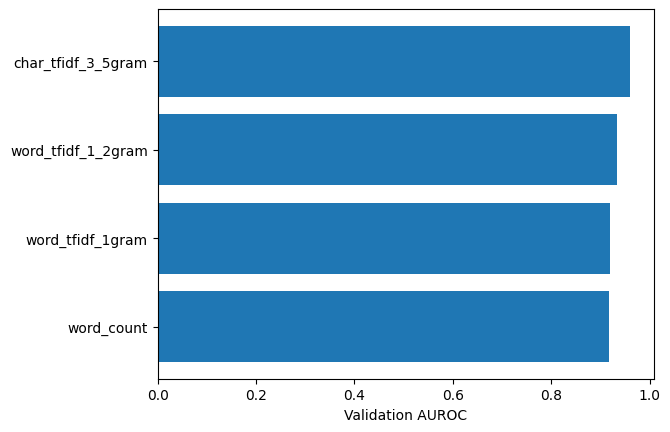

In [3]:
# some quick ensembles
for weight in [0, 0.25, 0.5, 0.75, 1]:
    p = (1-weight) * p_char + weight * p_word
    print('word weight', weight, 'AUC', round(roc_auc_score(y_val, p), 5))

plt.barh(comparison['Features'], comparison['Val AUC'])
plt.xlabel('Validation AUROC')
plt.show()


In [4]:
# first Kaggle try - character TF-IDF only (~0.842 public AUROC)
char_full = Pipeline([
    ('hash', HashingVectorizer(analyzer='char', ngram_range=(3, 5),
                               n_features=2**17, alternate_sign=False, norm=None)),
    ('tfidf', TfidfTransformer(sublinear_tf=True)),
    ('clf', LogisticRegression(C=1.0, max_iter=1000,
                               solver='liblinear', random_state=42))
])
char_full.fit(train['text'].astype(str), train['label'])
p_char_full_test = char_full.predict_proba(test['text'].astype(str))[:, 1]

pd.DataFrame({'id': test['id'], 'label': p_char_full_test}).to_csv(
    'char_tfidf_3-5gram_hash131072_logreg_v1.csv', index=False
)
print('saved first character model predictions')

saved first character model predictions
